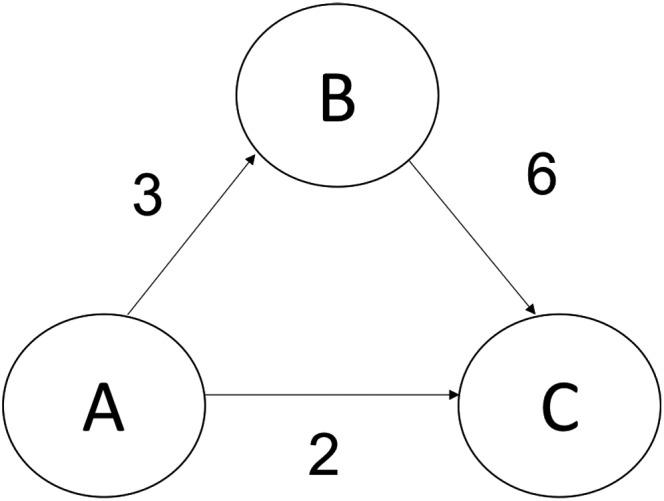

In [ ]:

import heapq
import time
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display, clear_output

# STEP 1: Create a small road network for demonstration
# These distances are illustrative, not actual road measurements.

graph = {
    "Karachi": {"Hyderabad": 165, "Sukkur": 450},
    "Hyderabad": {"Karachi": 165, "Sukkur": 300},
    "Sukkur": {
        "Karachi": 450,
        "Hyderabad": 300,
        "Multan": 350,
        "Quetta": 390
    },
    "Quetta": {"Sukkur": 390, "Multan": 600},
    "Multan": {"Sukkur": 350, "Quetta": 600,
               "Lahore": 340, "Faisalabad": 240},
    "Faisalabad": {"Multan": 240, "Lahore": 180,
                   "Islamabad": 320},
    "Lahore": {"Multan": 340, "Faisalabad": 180,
               "Islamabad": 375},
    "Islamabad": {"Lahore": 375, "Faisalabad": 320,
                  "Peshawar": 185},
    "Peshawar": {"Islamabad": 185}
}

# STEP 2: Estimated distance from each city to Lahore
# h(n) helps A* decide which city looks promising.

h = {
    "Karachi": 800,
    "Hyderabad": 650,
    "Sukkur": 500,
    "Quetta": 600,
    "Multan": 250,
    "Faisalabad": 140,
    "Lahore": 0,
    "Islamabad": 280,
    "Peshawar": 400
}

start = "Karachi"
goal = "Lahore"

# STEP 3: Prepare the graph drawing
G = nx.Graph()

for city, neighbors in graph.items():
    for neighbor, distance in neighbors.items():
        G.add_edge(city, neighbor, weight=distance)

positions = {
    "Karachi": (0, 0),
    "Hyderabad": (1.5, 1),
    "Sukkur": (3, 2),
    "Quetta": (2, 3.5),
    "Multan": (5, 2),
    "Faisalabad": (6.5, 3.5),
    "Lahore": (8, 4),
    "Islamabad": (8, 6),
    "Peshawar": (9.5, 7)
}

# STEP 4: A* Search with a record of each step
def a_star_demo(start, goal):

    # Each queue item: (f score, g score, city, path)
    queue = [(h[start], 0, start, [start])]

    best_g = {start: 0}
    expanded = set()
    steps = []

    while queue:
        f_score, g_score, city, path = heapq.heappop(queue)

        # Ignore an old queue entry
        if g_score != best_g.get(city):
            continue

        steps.append({
            "city": city,
            "g": g_score,
            "h": h[city],
            "f": g_score + h[city],
            "path": path.copy(),
            "expanded": expanded.copy(),
            "frontier": {
                item[2] for item in queue
                if item[1] == best_g.get(item[2])
            }
        })

        if city == goal:
            return path, g_score, steps

        expanded.add(city)

        for neighbor, distance in graph[city].items():
            new_g = g_score + distance

            if new_g < best_g.get(neighbor, float("inf")):
                best_g[neighbor] = new_g

                new_f = new_g + h[neighbor]

                heapq.heappush(
                    queue,
                    (new_f, new_g, neighbor, path + [neighbor])
                )

    return None, None, steps


# STEP 5: Run the demonstration
route, total_distance, steps = a_star_demo(start, goal)

for number, step in enumerate(steps, start=1):

    clear_output(wait=True)

    current = step["city"]
    path = step["path"]
    explored = step["expanded"] | {current}
    frontier = step["frontier"]

    # Keep the current city visually distinct
    colors = []
    for city in G.nodes():
        if city == current:
            colors.append("orange")
        elif city in path:
            colors.append("lightgreen")
        elif city in frontier:
            colors.append("yellow")
        elif city in explored:
            colors.append("lightblue")
        else:
            colors.append("lightgray")

    plt.figure(figsize=(12, 6))

    nx.draw(
        G, positions,
        with_labels=True,
        node_color=colors,
        node_size=2300,
        font_size=9,
        font_weight="bold"
    )

    edge_labels = nx.get_edge_attributes(G, "weight")
    nx.draw_networkx_edge_labels(
        G, positions, edge_labels=edge_labels,
        font_size=8
    )

    plt.title(
        f"A* Search: Step {number} | "
        f"Current city: {current}"
    )
    plt.show()

    print("START:", start, "| DESTINATION:", goal)
    print("Current city:", current)
    print("g(n) - distance travelled:", step["g"], "km")
    print("h(n) - estimated remaining:", step["h"], "km")
    print("f(n) = g(n) + h(n):", step["f"], "km")
    print("Current route:", " -> ".join(path))

    print("\nOrange = Current city")
    print("Green = Current route")
    print("Yellow = Waiting to be explored")
    print("Blue = Previously explored")
    print("Grey = Not explored yet")

    if current == goal:
        print("\nDESTINATION REACHED!")
        print("Final route:", " -> ".join(route))
        print("Total distance:", total_distance, "km")
        break

    time.sleep(2)


: 

# **DIJKSTRA'S ALGORITHM IMPLEMENTATION**

In [ ]:

import csv
import heapq
from google.colab import files
import ipywidgets as widgets
from IPython.display import display, clear_output

# ---------- Step 1: Upload the CSV file ----------
print("Please upload 'pakistan-cities-dataset.csv':")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# ---------- Step 2: Build the graph ----------
# graph = {city: {neighbor: distance, ...}, ...}
graph = {}

with open(filename) as f:
    reader = csv.reader(f)
    next(reader)  # skip the header row
    for row in reader:
        if not row:           # skip empty lines
            continue
        city1, city2, km = row[0].strip(), row[1].strip(), int(row[2])
        graph.setdefault(city1, {})[city2] = km  # road from city1 to city2
        graph.setdefault(city2, {})[city1] = km  # and back (roads go both ways)

# ---------- Step 3: Dijkstra's algorithm ----------
def dijkstra(start, end):
    # Each item in the queue: (distance so far, current city, path so far)
    queue = [(0, start, [start])]
    visited = set()

    while queue:
        cost, city, path = heapq.heappop(queue)  # take the closest city

        if city == end:           # reached the destination
            return path, cost

        if city in visited:       # already handled this city
            continue
        visited.add(city)

        for neighbor, km in graph[city].items():
            if neighbor not in visited:
                heapq.heappush(queue, (cost + km, neighbor, path + [neighbor]))

    return None, None             # no route exists

# ---------- Step 4: Simple user interface ----------
cities = sorted(graph.keys())

start_box = widgets.Dropdown(options=cities, description="From:")
end_box = widgets.Dropdown(options=cities, description="To:")
button = widgets.Button(description="Find Shortest Route")
output = widgets.Output()

def on_click(b):
    with output:
        clear_output()
        if start_box.value == end_box.value:
            print("Please choose two different cities.")
            return
        path, km = dijkstra(start_box.value, end_box.value)
        if path:
            print("Route:", " -> ".join(path))
            print("Total distance:", km, "km")
        else:
            print("No route found.")

button.on_click(on_click)
display(start_box, end_box, button, output)

Please upload 'pakistan-cities-dataset.csv':


Saving pakistan-cities-dataset.csv to pakistan-cities-dataset (3).csv


Dropdown(description='From:', options=('Abbottabad', 'Attock', 'Badin', 'Bagh', 'Bahawalnagar', 'Bahawalpur', …

Dropdown(description='To:', options=('Abbottabad', 'Attock', 'Badin', 'Bagh', 'Bahawalnagar', 'Bahawalpur', 'B…

Button(description='Find Shortest Route', style=ButtonStyle())

Output()

# **ADVANCED A static SEARCH WITH HAVERSINE HEURISTIC**

In [ ]:
import csv
import heapq
import math
from google.colab import files
import ipywidgets as widgets
from IPython.display import display, clear_output

# STEP 1: Upload the CSV file
print("Upload pakistan-cities-dataset.csv")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# STEP 2: Build the graph
graph = {}

with open(filename, encoding="utf-8-sig") as f:
    reader = csv.DictReader(f)

    for row in reader:
        city1 = row["origin"].strip()
        city2 = row["destination"].strip()
        km = float(row["distance"])

        graph.setdefault(city1, {})[city2] = km
        graph.setdefault(city2, {})[city1] = km

print("Cities loaded:", len(graph))

# STEP 3: Add city coordinates
# Format: "City": (latitude, longitude)
# Add coordinates for your dataset's cities here.
coordinates = {
    "Karachi": (24.8607, 67.0011),
    "Lahore": (31.5204, 74.3587),
    "Islamabad": (33.6844, 73.0479),
    "Rawalpindi": (33.5651, 73.0169),
    "Peshawar": (34.0151, 71.5249),
    "Quetta": (30.1798, 66.9750),
    "Multan": (30.1575, 71.5249),
    "Faisalabad": (31.4504, 73.1350),
    "Hyderabad": (25.3960, 68.3578),
    "Sukkur": (27.7052, 68.8574),
    "Gwadar": (25.1264, 62.3225),
    "Murree": (33.9073, 73.3943),
    "Abbottabad": (34.1688, 73.2215),
    "Mardan": (34.1989, 72.0231),
    "Sialkot": (32.4945, 74.5229)
}

# STEP 4: Calculate estimated straight-line distance
def heuristic(city, destination):
    # If either coordinate is missing, use zero.
    # Zero is safe but gives no A* guidance.
    if city not in coordinates or destination not in coordinates:
        return 0

    lat1, lon1 = coordinates[city]
    lat2, lon2 = coordinates[destination]

    # Haversine formula: distance in kilometres
    lat1, lon1, lat2, lon2 = map(
        math.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        math.sin(dlat / 2) ** 2
        + math.cos(lat1) * math.cos(lat2)
        * math.sin(dlon / 2) ** 2
    )

    return 6371 * 2 * math.asin(
        math.sqrt(min(1, a))
    )

# STEP 5: A* Search algorithm
def a_star(start, end):

    # Queue stores:
    # (estimated total cost, actual cost, city, path)
    queue = [(heuristic(start, end), 0, start, [start])]

    # Best known actual distance to each city
    best_distance = {start: 0}

    # Count cities expanded
    expanded = 0

    while queue:
        f_score, cost, city, path = heapq.heappop(queue)

        # Ignore an outdated queue entry
        if cost != best_distance.get(city):
            continue

        expanded += 1

        # Destination reached
        if city == end:
            return path, cost, expanded

        # Check connected cities
        for neighbor, km in graph[city].items():
            new_cost = cost + km

            # Update if a shorter route to this city is found
            if new_cost < best_distance.get(neighbor, float("inf")):
                best_distance[neighbor] = new_cost

                estimated_total = (
                    new_cost + heuristic(neighbor, end)
                )

                heapq.heappush(
                    queue,
                    (
                        estimated_total,
                        new_cost,
                        neighbor,
                        path + [neighbor]
                    )
                )

    return None, None, expanded

# STEP 6: Create the user interface
cities = sorted(graph.keys())

start_box = widgets.Dropdown(
    options=cities,
    description="From:"
)

end_box = widgets.Dropdown(
    options=cities,
    description="To:"
)

button = widgets.Button(
    description="Find Route Using A*",
    button_style="success"
)

output = widgets.Output()

def on_click(b):
    with output:
        clear_output()

        if start_box.value == end_box.value:
            print("Please choose two different cities.")
            return

        path, km, expanded = a_star(
            start_box.value,
            end_box.value
        )

        if path:
            print("Route:", " -> ".join(path))
            print("Total distance:", km, "km")
            print("Cities expanded:", expanded)
        else:
            print("No route found.")

button.on_click(on_click)

display(start_box, end_box, button, output)

Upload pakistan-cities-dataset.csv


Saving pakistan-cities-dataset.csv to pakistan-cities-dataset (5).csv
Cities loaded: 112


Dropdown(description='From:', options=('Abbottabad', 'Attock', 'Badin', 'Bagh', 'Bahawalnagar', 'Bahawalpur', …

Dropdown(description='To:', options=('Abbottabad', 'Attock', 'Badin', 'Bagh', 'Bahawalnagar', 'Bahawalpur', 'B…

Button(button_style='success', description='Find Route Using A*', style=ButtonStyle())

Output()